# 07: RQ3 results, does training the retriever widen coverage?

RQ3 asks whether fine-tuning the **first-stage retriever** on the authors' labels puts more credited papers into the top 100, the shortlist a reranker works on. This matters because of the coverage ceiling: a reranker only reorders the shortlist, so for every question
$$\text{Recall@20}_{\text{final}} \le \text{Recall@100}_{\text{retriever}}.$$

**What was trained.** For each of the 5 test folds, a Qwen3-Embedding-0.6B was fully fine-tuned with InfoNCE on that fold's training questions (in-batch plus author-rejected negatives, $\tau = 0.05$, `configs/rq3.yaml`), early-stopped on its inner validation questions, then used to re-encode all 190,896 papers and retrieve the top 100 for that fold's **test** questions only. Concatenating the 5 folds gives one held-out shortlist per question.

**Three shortlists are compared** (same questions, date filter, instruction, paper text and depth):
- **B**: frozen Qwen3-Embedding-4B, the pipeline baseline the plan names ("Recall@100 vs B").
- **B06**: frozen Qwen3-Embedding-0.6B, the same model RQ3 starts from. RQ3 vs B06 isolates the effect of training; RQ3 vs B mixes training with a 4B to 0.6B switch (decision log, Nov 20).
- **RQ3**: the fine-tuned 0.6B, one model per fold.

Inputs: `results/shortlist_rq3.parquet`, `shortlist_rq3_fold{0..4}.parquet`, `metrics_rq3.csv`, `train_history_rq3.csv` (written by `scripts/train_retrievers.py`, folds 0 and 1 on an A40, folds 2 to 4 on RTX A5000 cards with gradient caching, decision log Nov 25), `shortlist_B.parquet`, `shortlist_B06.parquet`, their metric files, and `results/folds.csv`.

The second half of the item, the **full pipeline** (the RQ3 shortlist rescored by the best trained reranker), needs a GPU run that has not happened yet; its section at the end reads the results automatically once they exist.

Paired bootstrap intervals over projects come in notebook 08 (`insight.stats`, Mon Nov 30), so differences here are point estimates without intervals.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from insight import data, metrics, diagnose, train_reranker as T
pd.set_option("display.precision", 4)
R = data.ROOT / "results"
ds = data.load()
table = ds.table
runs = {"B": pd.read_parquet(R / "shortlist_B.parquet"),
        "B06": pd.read_parquet(R / "shortlist_B06.parquet"),
        "RQ3": pd.read_parquet(R / "shortlist_rq3.parquet")}
per_q = {"B": pd.read_csv(R / "metrics_B.csv", index_col="query_id"),
         "B06": pd.read_csv(R / "metrics_B06.csv", index_col="query_id"),
         "RQ3": pd.read_csv(R / "metrics_rq3.csv", index_col="query_id")}
splits = T.splits_from_csv(R / "folds.csv")
fold_of = {q: s.fold for s in splits for q in s.test}
for name, run in runs.items():
    n = run.groupby("query_id").size()
    print(f"{name}: {len(run)} rows, {run.query_id.nunique()} questions, {n.min()} to {n.max()} papers per question")

B: 89400 rows, 894 questions, 100 to 100 papers per question
B06: 89400 rows, 894 questions, 100 to 100 papers per question
RQ3: 89400 rows, 894 questions, 100 to 100 papers per question


## Sanity checks on the RQ3 shortlist

1. **Held out.** Each question's RQ3 shortlist must come from the retriever of the fold that held it out (`fold` column equals the question's test fold in `results/folds.csv`), and the combined file must equal the 5 per-fold files stacked. `insight.train_reranker.check_shortlist_fold` is the same check the reranking script now runs before rescoring a per-fold shortlist.
2. **Metrics.** Recomputing them from the shortlist with `insight.metrics` must give `metrics_rq3.csv` exactly.
3. **Ranks** are 1 to 100 in descending score order.
4. **Date filter.** No shortlisted paper may be an unlabeled paper published after the question's source paper (`configs/data.yaml`).

In [2]:
rq3 = runs["RQ3"]
for s in splits:
    T.check_shortlist_fold(rq3, s.fold, s.test)
print("every question's RQ3 rows come from its own test fold:", (rq3.fold == rq3.query_id.map(fold_of)).all())
stacked = pd.concat([pd.read_parquet(R / f"shortlist_rq3_fold{f}.parquet") for f in range(5)], ignore_index=True)
key = ["query_id", "rank"]
same = stacked.sort_values(key).reset_index(drop=True).equals(rq3.sort_values(key).reset_index(drop=True))
print("combined file equals the 5 per-fold files stacked:", same)

cols = ["recall@5", "recall@20", "recall@100", "ndcg@20", "mrr"]
ranked = {q: g.sort_values("rank").doc_id.tolist() for q, g in rq3.groupby("query_id")}
recomputed = metrics.evaluate(ranked, table.positives.to_dict())
committed = per_q["RQ3"]
print("max |recomputed - committed| over", len(committed), "questions:",
      (recomputed.loc[committed.index, cols] - committed[cols]).abs().to_numpy().max())

ok_rank = rq3.groupby("query_id").apply(lambda g: (g.sort_values("rank").score.diff().dropna() <= 0).all() and sorted(g["rank"]) == list(range(1, 101)))
print("questions with ranks 1..100 in descending score order:", int(ok_rank.sum()), "of", len(ok_rank))

pos_of = {d: i for i, d in enumerate(ds.corpus.id)}
mask = data.mask_fn(ds.corpus, table, data.DataConfig.from_yaml(data.ROOT / "configs" / "data.yaml"))
violations = sum((~mask(q)[[pos_of[d] for d in g.doc_id]]).sum() for q, g in rq3.groupby("query_id"))
print("shortlisted papers that the date filter forbids:", int(violations))

every question's RQ3 rows come from its own test fold: True
combined file equals the 5 per-fold files stacked: True


max |recomputed - committed| over 894 questions: 0.0


questions with ranks 1..100 in descending score order: 894 of 894


shortlisted papers that the date filter forbids: 0


## Headline: RQ3 against B and B06

Means over questions, core (207) and subfield (687) separately. **Recall@K** is (credited papers in the top $K$) / (all credited papers) for one question, averaged; **nDCG@20** also rewards putting credited papers higher (a hit at rank $r$ counts $1/\log_2(r+1)$, normalized by the best possible order); **MRR** is the mean of $1/\text{rank}$ of the first credited paper. Recall@100 is the coverage ceiling, the number RQ3 is about.

In [3]:
side = pd.concat({k: v.groupby("kind")[cols].mean() for k, v in per_q.items()})
side

recall@5  recall@20  recall@100  ndcg@20     mrr
    kind                                                      
B   core        0.1846     0.3785      0.5971   0.2539  0.3162
    subfield    0.2233     0.4489      0.6967   0.3663  0.4965
B06 core        0.1887     0.3270      0.5288   0.2345  0.3180
    subfield    0.1733     0.3667      0.5971   0.2957  0.4226
RQ3 core        0.1775     0.3400      0.5420   0.2351  0.2981
    subfield    0.1962     0.3913      0.6245   0.3186  0.4535

In [4]:
diffs = pd.concat({"RQ3 - B06 (training)": side.loc["RQ3"] - side.loc["B06"],
                   "RQ3 - B (vs pipeline baseline)": side.loc["RQ3"] - side.loc["B"]})
diffs

recall@5  recall@20  recall@100  \
                               kind                                        
RQ3 - B06 (training)           core       -0.0112     0.0130      0.0132   
                               subfield    0.0228     0.0246      0.0275   
RQ3 - B (vs pipeline baseline) core       -0.0070    -0.0385     -0.0550   
                               subfield   -0.0271    -0.0576     -0.0721   

                                         ndcg@20     mrr  
                               kind                       
RQ3 - B06 (training)           core       0.0006 -0.0199  
                               subfield   0.0228  0.0309  
RQ3 - B (vs pipeline baseline) core      -0.0188 -0.0180  
                               subfield  -0.0477 -0.0430

In [5]:
for kind in ["core", "subfield"]:
    b06, rq, b = (side.loc[(k, kind), "recall@100"] for k in ["B06", "RQ3", "B"])
    print(f"{kind}: Recall@100 B06 {b06:.4f} -> RQ3 {rq:.4f} (B {b:.4f}); "
          f"training closes {(rq - b06) / (b - b06):.1%} of the B06-to-B gap")

core: Recall@100 B06 0.5288 -> RQ3 0.5420 (B 0.5971); training closes 19.4% of the B06-to-B gap
subfield: Recall@100 B06 0.5971 -> RQ3 0.6245 (B 0.6967); training closes 27.6% of the B06-to-B gap


The last line reads: of the distance between the frozen 0.6B and the frozen 4B on Recall@100, what fraction did fine-tuning the 0.6B cover. 100% would mean the trained 0.6B matches the 4B; above 100% would mean it beats it.

## Per fold

Each fold is a different trained model on different test questions. Folds 0 and 1 were trained on an A40 with one full-batch backward pass; folds 2 to 4 on RTX A5000 cards with gradient caching, which computes the same gradients (decision log, Nov 25). Per-fold numbers show whether the gain is consistent or carried by one or two folds.

In [6]:
by_fold = pd.concat({k: v.assign(fold=v.index.map(fold_of)).groupby(["kind", "fold"])["recall@100"].mean()
                     for k, v in per_q.items()}, axis=1)
by_fold["RQ3 - B06"] = by_fold.RQ3 - by_fold.B06
by_fold["RQ3 - B"] = by_fold.RQ3 - by_fold.B
by_fold["n"] = per_q["RQ3"].assign(fold=per_q["RQ3"].index.map(fold_of)).groupby(["kind", "fold"]).size()
by_fold

B     B06     RQ3  RQ3 - B06  RQ3 - B    n
kind     fold                                                 
core     0     0.5989  0.5477  0.5509     0.0032  -0.0480   42
         1     0.6478  0.5673  0.5937     0.0263  -0.0541   42
         2     0.5499  0.5178  0.5164    -0.0014  -0.0335   41
         3     0.5677  0.5250  0.5368     0.0118  -0.0309   41
         4     0.6199  0.4849  0.5111     0.0261  -0.1089   41
subfield 0     0.7037  0.5984  0.6340     0.0356  -0.0697  140
         1     0.7395  0.6172  0.6692     0.0520  -0.0703  134
         2     0.7257  0.6008  0.6068     0.0060  -0.1190  140
         3     0.6419  0.5619  0.5954     0.0335  -0.0466  137
         4     0.6724  0.6074  0.6184     0.0110  -0.0540  136

## Per question: how often does training help?

For each question, compare Recall@100 of RQ3 with B06 and with B: higher, equal or lower. A mean gain can come from many small wins or a few large ones; this table shows which. Equal is common because a question with few credited papers can only take a few recall values.

In [7]:
def wtl(a, b):
    d = per_q[a]["recall@100"] - per_q[b].loc[per_q[a].index, "recall@100"]
    kind = per_q[a].kind
    return pd.DataFrame({"higher": (d > 0).groupby(kind).mean(), "equal": (d == 0).groupby(kind).mean(),
                         "lower": (d < 0).groupby(kind).mean(), "n": d.groupby(kind).size()})
pd.concat({"RQ3 vs B06": wtl("RQ3", "B06"), "RQ3 vs B": wtl("RQ3", "B")})

higher   equal   lower    n
           kind                                 
RQ3 vs B06 core      0.2126  0.6280  0.1594  207
           subfield  0.3130  0.3959  0.2911  687
RQ3 vs B   core      0.1304  0.5894  0.2802  207
           subfield  0.1732  0.4032  0.4236  687

## What early stopping chose

Training ran for at most 3 epochs; each epoch ended with validation Recall@$k'$ ($k' = 11$) of the inner validation questions inside a pool of about 21.5k papers (a proxy for full-corpus Recall@100, decision log Nov 18), and the best epoch was kept. Step 0 is the frozen model before any update.

In [8]:
h = pd.read_csv(R / "train_history_rq3.csv")
best = h.loc[h.groupby("fold").val_recall.idxmax()].set_index("fold")
start = h[h.step == 0].set_index("fold")
last = h.loc[h.groupby("fold").step.idxmax()].set_index("fold")
pd.DataFrame({"val recall, step 0": start.val_recall, "best epoch": best.epoch.astype(int),
              "val recall, best": best.val_recall, "val recall, last epoch": last.val_recall,
              "train loss, epoch 1": h[h.epoch == 1].set_index("fold").train_loss,
              "train loss, last": last.train_loss})

,"val recall, step 0",best epoch,"val recall, best","val recall, last epoch","train loss, epoch 1","train loss, last"
fold,,,,,,
0,0.4113,1,0.4782,0.4476,1.4989,0.0983
1,0.4567,1,0.4919,0.4739,1.5243,0.0965
2,0.3574,2,0.4181,0.4032,1.3678,0.0809
3,0.4651,1,0.4773,0.4516,1.5160,0.0834
4,0.3626,2,0.4013,0.3828,1.5031,0.0885


## Which credited papers cross the rank-100 line?

Counted over credited (question, paper) **pairs** (a question with 10 credited papers weighs more than one with 1). For each pair: is it in the top 100 of the frozen model, of RQ3, both or neither. "Gained" pairs are ones training brought into the shortlist, "lost" ones it pushed out.

In [9]:
def in_top(run, k=100):
    r = run[run["rank"] <= k]
    return set(zip(r.query_id, r.doc_id))
pairs = diagnose.credited_ranks(runs["B"], table)[["query_id", "kind", "doc_id"]]
key = list(zip(pairs.query_id, pairs.doc_id))
for k in runs:
    top = in_top(runs[k]); pairs[k] = [x in top for x in key]

def crossing(a, b):
    lab = np.select([pairs[a] & pairs[b], pairs[b], pairs[a]], ["both", f"{b} only", f"{a} only"], "neither")
    t = pd.crosstab(pairs.kind, lab, normalize="index")[["both", f"{b} only", f"{a} only", "neither"]]
    t[f"{b} alone"] = t["both"] + t[f"{b} only"]
    t["union"] = 1 - t["neither"]
    t["n pairs"] = pairs.groupby("kind").size()
    return t
crossing("B06", "RQ3")

col_0,both,RQ3 only,B06 only,neither,RQ3 alone,union,n pairs
kind,,,,,,,
core,0.4130,0.1074,0.0908,0.3888,0.5204,0.6112,661
subfield,0.4897,0.1317,0.1195,0.2591,0.6214,0.7409,4184


In [10]:
crossing("B", "RQ3")

col_0,both,RQ3 only,B only,neither,RQ3 alone,union,n pairs
kind,,,,,,,
core,0.4478,0.0726,0.1362,0.3434,0.5204,0.6566,661
subfield,0.5418,0.0796,0.1761,0.2024,0.6214,0.7976,4184


The second table asks whether the trained 0.6B finds credited papers the frozen 4B misses ("RQ3 only"). The union column is a share of pairs and an upper bound on what merging the two top-100 lists could reach; a merged list holds up to 200 papers, so it is not a like-for-like Recall@100.

## Rank bins under each retriever

The RQ1 view: each credited pair's bin. Rank 1 to 20 is found; 21 to 100 is on the shortlist but too low (a reranker could fix it); beyond 100 is out of the reranker's reach.

In [11]:
bins = {}
for k in runs:
    rb = diagnose.credited_ranks(runs[k], table)
    rb["bin"] = diagnose.rank_bin(rb["rank"])
    bins[k] = pd.crosstab(rb.kind, rb.bin, normalize="index")
pd.concat(bins)

bin           1 to 20  21 to 100  beyond 100
    kind                                    
B   core       0.3631     0.2209      0.4160
    subfield   0.4500     0.2679      0.2820
B06 core       0.3116     0.1921      0.4962
    subfield   0.3719     0.2373      0.3908
RQ3 core       0.3238     0.1967      0.4796
    subfield   0.3762     0.2452      0.3786

## Recall by depth

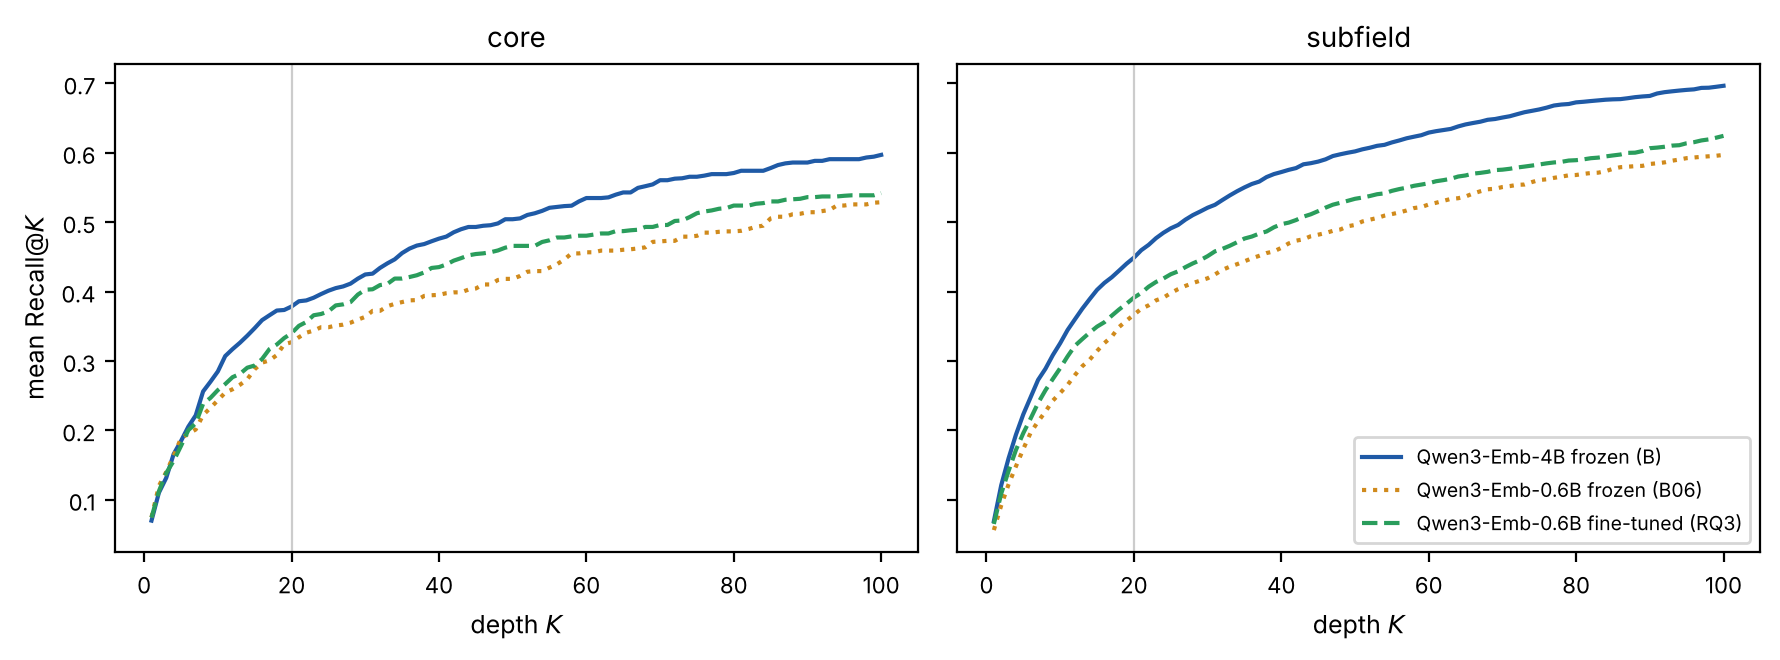

In [12]:
def recall_curve(run, ks=range(1, 101)):
    p = diagnose.credited_ranks(run, table)
    n_pos = p.groupby("query_id").size()
    curve = pd.DataFrame({k: p.assign(h=p["rank"] <= k).groupby("query_id").h.sum() / n_pos for k in ks})
    return curve.groupby(table.kind.loc[curve.index]).mean().T

curves = {k: recall_curve(runs[k]) for k in runs}
for k in runs:  # the curve must agree with the per-question metric files at K = 20 and 100
    for K in (20, 100):
        assert np.allclose(curves[k].loc[K], per_q[k].groupby("kind")[f"recall@{K}"].mean().loc[curves[k].columns])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
styles = {"B": ("Qwen3-Emb-4B frozen (B)", "#1f5aa6", "-"), "B06": ("Qwen3-Emb-0.6B frozen (B06)", "#d08a1c", ":"),
          "RQ3": ("Qwen3-Emb-0.6B fine-tuned (RQ3)", "#2a9d5c", "--")}
for ax, kind in zip(axes, ["core", "subfield"]):
    for k, (lab, col, ls) in styles.items():
        ax.plot(curves[k].index, curves[k][kind], color=col, ls=ls, label=lab)
    ax.axvline(20, color="#cccccc", lw=0.8); ax.set_title(kind, fontsize=10); ax.set_xlabel("depth $K$", fontsize=9)
    ax.tick_params(labelsize=8)
axes[0].set_ylabel("mean Recall@$K$", fontsize=9); axes[1].legend(fontsize=7, loc="lower right")
fig.tight_layout()
(R / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(R / "figures" / "recall_by_depth_B_B06_rq3.png", dpi=150)
plt.show()

<small>Figure: mean Recall@$K$ (y) against shortlist depth $K$ (x), left core questions (207), right subfield questions (687), each question scored held out. Solid blue: frozen Qwen3-Embedding-4B (condition B); orange dotted: frozen Qwen3-Embedding-0.6B (B06); green dashed: Qwen3-Embedding-0.6B fine-tuned per fold with InfoNCE (RQ3). Vertical line: $K = 20$. Saved as `results/figures/recall_by_depth_B_B06_rq3.png`.</small>

## Full pipeline: the RQ3 shortlist rescored by a trained reranker

The plan's last RQ3 step feeds each fold's RQ3 top 100 to the best reranker from D or E, using that fold's adapter (trained on the same training folds as the fold's retriever, so neither model saw the test question). Scoring needs a GPU, so it is H100 queue item 9: `scripts/train_rerankers.py --config configs/E_rq3.yaml` (score only, no training). E is the default because it has the highest Recall@20 of the trained rerankers on B's shortlist (table below); which reranker to stack, if any, is logged as NEEDS REVIEW.

For reference, the trained rerankers on **B's** shortlist, next to B's own order (from `notebooks/06_rq2_results.ipynb`'s inputs):

In [13]:
ref = {"B (no reranker)": per_q["B"]}
for k in ["C", "D", "E", "D_core"]:
    p = R / f"metrics_{k}.csv"
    if p.exists():
        ref[f"{k} on B"] = pd.read_csv(p, index_col="query_id")
ref["RQ3 (no reranker)"] = per_q["RQ3"]
for k in ["E_rq3", "D_rq3"]:
    p = R / f"metrics_{k}.csv"
    if p.exists():
        ref[f"{k[0]} on RQ3"] = pd.read_csv(p, index_col="query_id")
show = ["recall@20", "ndcg@20", "recall@100"] + (["pairwise_acc"])
pd.concat({k: v.groupby("kind")[[c for c in show if c in v]].mean() for k, v in ref.items()})

recall@20  ndcg@20  recall@100  pairwise_acc
                  kind                                                  
B (no reranker)   core         0.3785   0.2539      0.5971           NaN
                  subfield     0.4489   0.3663      0.6967           NaN
C on B            core         0.3432   0.2296      0.5971        0.4948
                  subfield     0.4042   0.3078      0.6967        0.5643
D on B            core         0.2346   0.1408      0.5971        0.6471
                  subfield     0.2771   0.2027      0.6967        0.6331
E on B            core         0.3061   0.1947      0.5971        0.6418
                  subfield     0.3773   0.2897      0.6967        0.6467
D_core on B       core         0.2051   0.1261      0.5971        0.6466
                  subfield     0.2249   0.1508      0.6967        0.5855
RQ3 (no reranker) core         0.3400   0.2351      0.5420           NaN
                  subfield     0.3913   0.3186      0.6245           NaN

In [14]:
missing = [k for k in ["E_rq3"] if not (R / f"metrics_{k}.csv").exists()]
print("full-pipeline results not in results/ yet:", missing if missing else "none")

full-pipeline results not in results/ yet: ['E_rq3']


Reading the table: Recall@100 of a reranked run equals its shortlist's (a reranker reorders the same 100 papers), so it is the ceiling for that row's Recall@20. Until `metrics_E_rq3.csv` exists, the RQ3 rows show the trained retriever's own order only.

## Summary

All numbers are outputs of the cells above.

- **Checks.** Every question's RQ3 shortlist comes from the retriever of its own test fold, the combined file equals the 5 per-fold files, recomputing the metrics reproduces `metrics_rq3.csv` exactly (max difference 0.0), all 894 questions have ranks 1 to 100 in score order, and no shortlisted paper breaks the date filter.
- **Training widens coverage a little.** Recall@100 goes from 0.5288 (frozen 0.6B) to 0.5420 (fine-tuned) on core questions ($+0.0132$) and from 0.5971 to 0.6245 on subfield questions ($+0.0275$). Recall@20 rises by $+0.0130$ and $+0.0246$. Core MRR falls ($-0.0199$) and core Recall@5 falls ($-0.0112$).
- **It does not reach the frozen 4B.** The trained 0.6B stays below B on every metric: Recall@100 $-0.0550$ (core) and $-0.0721$ (subfield). Training closes 19.4% (core) and 27.6% (subfield) of the gap between the frozen 0.6B and the frozen 4B. So the RQ3 shortlist as trained here does **not** widen coverage relative to the pipeline's current shortlist.
- **The gain is uneven.** Per fold, RQ3 minus B06 on core Recall@100 ranges from $-0.0014$ (fold 2) to $+0.0263$ (fold 1); on subfield from $+0.0060$ (fold 2) to $+0.0520$ (fold 1). Per question, RQ3 beats B06 on 21.3% and loses on 15.9% of core questions (62.8% equal), and beats it on 31.3% and loses on 29.1% of subfield questions.
- **Training reshuffles more than it adds.** Of credited subfield pairs, 13.2% enter the top 100 only after training and 12.0% leave it (core: 10.7% enter, 9.1% leave).
- **But it finds papers the 4B misses.** 7.3% (core) and 8.0% (subfield) of credited pairs are in RQ3's top 100 and not in B's. The union of the two lists holds 65.7% and 79.8% of credited pairs, vs 58.4% and 71.8% for B alone (an upper bound for a merged list of up to 200 papers, not a Recall@100).
- **Early stopping kept epoch 1 in folds 0, 1 and 3 and epoch 2 in folds 2 and 4.** Validation recall fell in the last epoch in every fold while training loss dropped from about 1.4 to 1.5 after epoch 1 to about 0.08 to 0.10, so the model fits its roughly 3,100 training examples quickly and the validation proxy stops improving after one or two epochs.
- **Full pipeline: not run yet.** Rescoring the RQ3 shortlist with condition E's per-fold adapters is H100 queue item 9 (`configs/E_rq3.yaml`, score only). On B's shortlist no trained reranker beats B's own order (E: core Recall@20 0.3061 vs 0.3785), and RQ3's own order (0.3400) is already below B's, so the full pipeline is not expected to beat B; whether to run it with E, D or not at all is logged as NEEDS REVIEW.

What this supports, before intervals (notebook 08): fine-tuning the 0.6B on about 3,100 examples per fold helps it a little, but model size matters more than training here, and the trained 0.6B is a weaker first stage than the frozen 4B. The papers it finds that B misses suggest a merged or trained-4B shortlist as a possible next step, which is outside the current plan and your call.